# Did post-training cause Qwen3's algorithm collapse? (demo of `method.py`)

Ask Qwen3-8B (chat template, thinking off) for a weighted shortest-path solver and 193 of its 200 correct programs are **Dijkstra**. Ask it for a path on a grid and all 200 are **BFS**. This experiment tests one explanation: *instruction tuning installed that collapse*. It compares **Qwen3-8B-Base** with **Qwen3-8B** in a 2×2 design that crosses the weights with the prompt format:

| | template-free prompt (docstring) | chat-template prompt |
|---|---|---|
| **base weights** | `base_tf` | `base_chat` |
| **instruct weights** | `instruct_tf` | `instruct_chat` |

All four arms get the same task text, the same 10 prompt paraphrases and the same sampling settings (T = 1.0, top-p 1.0). Every generated program runs on hidden tests (46 for this task). Two labellers then name the algorithm it implements: a runtime-signature labeller and an AST labeller. A blind LLM judge settles disagreements. Diversity is measured as the **Hill number of the correct programs**: `Hill_cc = exp(Shannon entropy of their algorithm labels)`. A value of 1.0 means every correct program uses the same algorithm. A value of 2.0 means two equally common algorithms.

The pre-registered test is `D_weights = Hill_cc(instruct_chat) − Hill_cc(base_chat)`. Both arms see identical chat tokens, so they differ only in the weights. A fifth arm, `instruct_chat_ban`, adds a ban such as *"Do not use Dijkstra."* to the prompt to show where the model goes instead.

**What `method.py` does.** It is the experiment's single entry point. Each GPU phase runs as a subprocess: vLLM generation, labelling, HF activation capture, steering, and a hash-committed forecast. Then `assemble()` collects everything into `method_out.json`. The GPU phases need both 8B models on a GPU (about 2.8 GPU-hours on an NVIDIA L4). This notebook therefore:

1. lists the pipeline steps as a dry run;
2. runs the CPU part of the `analysis` step on **100 real generated programs**, with the code copied unchanged from `src/stats_utils.py` and `src/analysis.py`. This covers per-arm Hill numbers with paraphrase-cluster bootstrap CIs, permutation χ² tests, the pre-registered verdict, the ban row and the hash check of the committed forecast;
3. runs `assemble()` to write `method_out.json`;
4. plots the demo numbers next to the full-run numbers.

**Full-run result on this task (T2, weighted shortest path):** `INSTALLED_BY_POST_TRAINING`, with `D_weights = −0.93 [−1.38, −0.46]`. Under the same chat tokens the base model is more diverse (Dijkstra 63/90 correct programs, Bellman-Ford 24/90, Hill_cc 2.09) than the instruct model (Dijkstra 193/200, Hill_cc 1.16). Post-training *concentrated* a mode the base model already preferred; it did not invent a new one. The Dijkstra ban raises Hill_cc from 1.16 to 1.99 with no loss in pass rate. The model substitutes Bellman-Ford, which the committed forecast predicted.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the version the experiment used)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- method.py's import block (unchanged)
import argparse
import json
import os
import platform
import subprocess
import sys
from pathlib import Path

from loguru import logger

# ---- imports of the src/ modules inlined below (common.py, stats_utils.py, analysis.py)
import hashlib
import math
import random
from typing import Iterable

import numpy as np

# ---- notebook only: timing and figures
import time

import matplotlib.pyplot as plt

## Demo data

`mini_demo_data.json` holds **100 real programs** for one task, **T2**: write `solve(n, edges, s, t)` that returns the shortest-path distance in a weighted directed graph. The programs come from five arms: `base_tf` 25, `base_chat` 25, `instruct_tf` 15, `instruct_chat` 20 and `instruct_chat_ban` 15. Each row is an original labelled row from `runs/labelled_*.jsonl`, with the generated text, the extracted program, the hidden-test result and the runtime, AST, judge and final labels.

The file also carries the small files that `method.py` and the analysis read from disk: prompts, the hidden tests, results files of the GPU phases, and the hash-committed forecast. Finally, `full_run_reference` holds the full-run numbers so the notebook can compare them with the demo.

**How the subset was chosen** (`make_mini_demo_data.py`, seed 0). For each arm the script takes a fixed number of correct programs per algorithm label, chosen so the arm's mix of correct programs stays close to the full run. It then adds failing programs in proportion to the arm's failing-label mix, spreading picks round-robin over the prompt paraphrases. Hill_cc counts correct programs only, so these quotas keep it meaningful at n = 11–20 per arm. The base arms therefore have **more passing programs than in the full run** (full-run pass rates: `base_tf` 8 %, `base_chat` 30 %), and **pass rates in this demo are not representative**.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-1/experiment-5/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["description"])
print(f"\ndataset: {data['dataset']}   files bundled: {len(data['files'])}")
for arm, s in data["selection"]["per_arm"].items():
    print(f"  {arm:18s} demo: {s['n_demo']:3d} programs ({s['n_demo_passed']:2d} pass)   "
          f"full run: {s['n_full_run']:3d} programs ({s['n_full_run_passed']:3d} pass)")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Demo subset of the post-training collapse screen (Qwen3-8B-Base vs Qwen3-8B, thinking off, T=1, top-p 1): 100 generated + labelled programs for ONE task (T2 weighted directed shortest path) across five arms, plus the small files method.py reads from disk. 'files' maps each path (relative to the experiment folder) to its content; the notebook writes them back to disk.

dataset: T2_weighted_shortest_path   files bundled: 27
  base_tf            demo:  25 programs (13 pass)   full run: 300 programs ( 25 pass)
  base_chat          demo:  25 programs (14 pass)   full run: 300 programs ( 90 pass)
  instruct_tf        demo:  15 programs (11 pass)   full run: 100 programs ( 72 pass)
  instruct_chat      demo:  20 programs (20 pass)   full run: 200 programs (200 pass)
  instruct_chat_ban  demo:  15 programs (15 pass)   full run: 100 programs (100 pass)


## Configuration

All tunable parameters are set here. `B_BOOT` and `N_PERM` match the original analysis. `ROWS_PER_ARM` caps how many demo programs each arm uses; `None` uses all 100. The full run used 300 / 300 / 100 / 200 / 100 programs per arm, which needs the GPU pipeline to generate. `DEMO_TASKS` replaces the hard-coded `("t1", "t2")` loops of the original, because the demo data covers T2 only.

In [5]:
# ---- all tunable parameters of the demo ----
DEMO_TASKS = ("t2",)    # tasks to analyse and assemble. Original: ("t1", "t2"); the demo data holds ONE dataset (T2)
ROWS_PER_ARM = None     # programs per arm taken from the demo data (None = all: 15-25 per arm, 100 in total).
                        # Full run: base_tf 300, base_chat 300, instruct_tf 100, instruct_chat 200, instruct_chat_ban 100
B_BOOT = 2000           # paraphrase-cluster bootstrap resamples per CI (original: 2000)
N_PERM = 10000          # permutations per chi-square test of two label distributions (original: 10000)
SECOND_JUDGE = False    # original: True (`analysis.py --second_judge` re-labels 40 audit programs with a second LLM
                        # judge over the OpenRouter API; needs an API key and src/judge.py)
RUN_GPU_STEPS = False   # True runs the original pipeline as subprocesses: needs the full repository (src/, .venv),
                        # a GPU with >= 23 GB and both 8B models (about 2.8 GPU-hours on an NVIDIA L4)
WS = Path.cwd() / "demo_workspace"  # stands in for the experiment folder (original: WS = Path(__file__).resolve().parent)

## Shared constants and helpers (`src/common.py`)

`method.py` imports its paths, model ids, label catalogues and decoding settings from `src/common.py`. This cell copies that module, with one change: the experiment folder `WS` comes from the config cell. The **label catalogues** fix the algorithms the labellers can assign. Anything outside a catalogue is `other`. For T2 the catalogue is `dijkstra, bellman_ford_spfa, bidir_dijkstra, floyd_warshall, dial`. `BANNED` / `SURVIVORS` define the ban experiment: Dijkstra is banned on T2, and the forecast is scored over the remaining algorithms. Helpers of `common.py` that only the GPU steps use are left out (`sha256_text`, `stable_seed`, `append_jsonl`, `utc_now`, `time_log`, `add_deviation`, `set_ram_limit` and `env_flag`).

In [6]:
"""Shared constants, paths and small helpers for the collapse screen (alternate 4: post-training)."""
# src/common.py — original: WS = Path(__file__).resolve().parent.parent; here WS is set in the config cell
SRC = WS / "src"
DATA = WS / "data"
TESTS = DATA / "tests"
REFS = DATA / "refs"
RUNS = WS / "runs"
PRED = WS / "predictions"
ACTS = WS / "activations"
RESULTS = WS / "results"
FIGS = WS / "figures"
LOGS = WS / "logs"
for _d in (DATA, TESTS, REFS, RUNS, PRED, ACTS, RESULTS, FIGS, LOGS):
    _d.mkdir(parents=True, exist_ok=True)

MB = "Qwen/Qwen3-8B-Base"
MI = "Qwen/Qwen3-8B"
N_LAYERS = 36
D_MODEL = 4096
EOS_IDS = [151645, 151643]  # <|im_end|>, <|endoftext|>
IM_START_ID = 151644
TASKS = ("t1", "t2")
TASK_NAMES = {"t1": "T1_unweighted_grid_path", "t2": "T2_weighted_shortest_path"}

T1_LABELS = ["bfs", "dfs", "bidir_bfs", "iddfs", "astar_greedy", "dijkstra_unit"]
T2_LABELS = ["dijkstra", "bellman_ford_spfa", "bidir_dijkstra", "floyd_warshall", "dial"]
CATALOGUE = {"t1": T1_LABELS, "t2": T2_LABELS}
BANNED = {"t1": "bfs", "t2": "dijkstra"}
BAN_COND = {"t1": "ban:BFS", "t2": "ban:Dijkstra"}
SURVIVORS = {"t1": ["dfs", "bidir_bfs", "iddfs", "astar_greedy", "dijkstra_unit"],
             "t2": ["bellman_ford_spfa", "bidir_dijkstra", "floyd_warshall", "dial"]}

DECODING = {"temperature": 1.0, "top_p": 1.0, "top_k": "disabled", "min_p": 0.0,
            "repetition_penalty": 1.0, "max_tokens": 1024, "thinking": "off"}


def setup_logging(name: str, level: str = "INFO") -> None:
    logger.remove()
    logger.add(sys.stdout, level=level, format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def read_jsonl(p: Path) -> list[dict]:
    if not p.exists():
        return []
    out = []
    with open(p) as f:
        for line in f:
            line = line.strip()
            if line:
                out.append(json.loads(line))
    return out


def write_jsonl(p: Path, rows: Iterable[dict]) -> None:
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")
    tmp.replace(p)


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float, float]:
    if n == 0:
        return (float("nan"), float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (p, max(0.0, c - h), min(1.0, c + h))

## Recreate the experiment folder from the demo data

`method.py` and the analysis exchange everything through files under the experiment folder. They read the labelled programs from `runs/`, the prompts and hidden tests from `data/`, the GPU-phase outputs from `results/` and the committed forecast from `predictions/`. Instead of rewriting those functions to take in-memory data, this cell writes the bundled files back to their original paths under `WS`, and the original code then runs unchanged. Each arm's rows are cut to `ROWS_PER_ARM`; the rows are pre-ordered so that any prefix is still stratified. The forecast file is written byte-exact, because the analysis checks its sha256 against the commit log.

In [7]:
for rel, f in data["files"].items():
    p = WS / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    if f["kind"] == "jsonl":    # labelled programs of one arm, cut to the configured size
        write_jsonl(p, f["content"][:ROWS_PER_ARM])
    elif f["kind"] == "json":
        p.write_text(json.dumps(f["content"], indent=1))
    else:                       # raw text, byte-exact (the hash-committed forecast and its logs)
        p.write_text(f["content"])
    n = f" ({len(read_jsonl(p))} programs)" if f["kind"] == "jsonl" else ""
    print(f"{p.stat().st_size:>9,d} B  {rel}{n}")
print("forecast sha256:", sha256_file(PRED / "predict_modal_ban.json"))
print("committed      :", json.loads((PRED / "hash_log.txt").read_text().splitlines()[-1])["sha256"])

   71,065 B  runs/labelled_base_tf__baseline.jsonl (25 programs)
  109,155 B  runs/labelled_base_chat__baseline.jsonl (25 programs)
   41,913 B  runs/labelled_instruct_tf__baseline.jsonl (15 programs)
   46,844 B  runs/labelled_instruct_chat__baseline.jsonl (20 programs)
   37,771 B  runs/labelled_instruct_chat__ban.jsonl (15 programs)
   37,307 B  data/prompts.json
      374 B  results/gen_meta_A.json
      374 B  results/gen_meta_B.json
      374 B  results/gen_meta_C.json
      374 B  results/gen_meta_A_EXT.json
    6,792 B  results/deviations.json


   35,353 B  results/sharpening_direction.json
    3,414 B  results/harness_calibration.json
      632 B  results/hook_tests.json
      613 B  results/special_token_norms_base.json
      613 B  results/special_token_norms_instruct.json


       67 B  results/judge_cost.json
      220 B  results/predict_guard_test.json
    5,879 B  results/labeller_gate.json
      759 B  results/manipulation_S.json
      587 B  results/manipulation_R.json
    1,465 B  results/manipulation_X.json
  554,185 B  data/tests/t2.json
    1,749 B  time_log.json
    6,255 B  predictions/predict_modal_ban.json
      161 B  predictions/hash_log.txt
       41 B  predictions/git_commit.txt
forecast sha256: 94854c80011087e08ae40c998d493605e39e4b6b2b6730a9d635969b539d4d47


committed      : 94854c80011087e08ae40c998d493605e39e4b6b2b6730a9d635969b539d4d47


## The pipeline (`method.py`)

`python method.py --all` runs the steps below in `ORDER`, each as a subprocess so that vLLM and HF never sit on the GPU together, and then calls `assemble()`. The run is resumable: finished requests and rows are skipped. `--step <name>` runs a single step, and `--assemble` rebuilds the outputs from the results on disk.

| step | what it does | needs |
|---|---|---|
| `prompts` | builds the prompts: 50 neutral paraphrases per task (P0–P9 are sampled) and 10 ban phrasings, each in chat-template and template-free form | CPU |
| `tests` | hidden tests (47 for T1, 46 for T2) and reference solutions | CPU |
| `calibrate` | per-test time limits from the reference solutions: max(1 s, 10× the reference time) | CPU |
| `gate` | labeller gate: the runtime and AST labellers must recognise 25 reference programs | CPU |
| `genA`, `genB` | vLLM sampling of the base arms (A) and instruct arms (B) | GPU |
| `label` | runs every program on the hidden tests; labels it (runtime + AST, LLM judge on disagreement) | CPU + judge API |
| `acts` | residual states at the last prompt token for both models → the instruct-minus-base direction δ per layer | GPU |
| `predict` | commits a forecast of where the instruct model lands under the ban, from base-model counts (sha256 + git) | CPU |
| `genC` | instruct model under the ban prompt (arm `instruct_chat_ban`) | GPU |
| `steerS`, `steerR`, `steerX`, `steerXNC` | HF steering: subtract c·δ over layers 8–28, norm-matched random controls, single-layer and R-only variants | GPU |
| `genAEXT` | extends the base arms to N = 300 | GPU |
| `analysis` | statistics, verdicts, BUY / PREDICT rows, figures → `results/analysis.json` | CPU (+ judge API for `--second_judge`) |
| `report` | README tables | CPU |

The next cell is the original code. `setup_logging("method")` comes from `main()` and sends log lines to the cell output and to `logs/method.log`.

In [8]:
PY = str(WS / ".venv" / "bin" / "python")
STEPS = {
    "prompts": [PY, "src/prompts.py"],
    "tests": [PY, "src/tasks.py"],
    "calibrate": [PY, "src/calibrate.py"],
    "gate": [PY, "src/labeller_gate.py"],
    "genA": [PY, "src/gen_vllm.py", "--phase", "A"],
    "genB": [PY, "src/gen_vllm.py", "--phase", "B"],
    "label": [PY, "src/label_score.py"],
    "acts": None,  # two processes, see run_step
    "predict": [PY, "src/predict_commit.py"],
    "genC": [PY, "src/gen_vllm.py", "--phase", "C"],
    "steerS": [PY, "src/steer_hf.py", "--stage", "S"],
    "steerR": [PY, "src/steer_hf.py", "--stage", "R", "--cstar", "t1=0.5,t2=0.5"],
    "steerX": [PY, "src/steer_hf.py", "--stage", "X", "--extra",
               "sharpenR:1.0:None:10;randomR:1.0:1:10;single18:0.25:None:5;single18:0.5:None:5;single18:1.0:None:5"],
    "genAEXT": [PY, "src/gen_vllm.py", "--phase", "A_EXT"],
    "steerXNC": [PY, "src/steer_hf.py", "--stage", "X", "--nocutoff", "--extra", "sharpenR:1.0:None:2"],
    "analysis": [PY, "src/analysis.py", "--second_judge"],
    "report": [PY, "src/report.py"],
}
ORDER = ["prompts", "tests", "calibrate", "gate", "genA", "genB", "label", "acts", "predict", "genC", "steerS", "label",
         "steerR", "steerX", "genAEXT", "steerXNC", "label", "analysis", "report"]


def run_step(name: str) -> None:
    logger.info(f"=== step {name}")
    if name == "acts":
        for m in ("base", "instruct"):
            subprocess.run([PY, "src/acts_hf.py", "--model", m], cwd=WS, check=True)
        return
    subprocess.run(STEPS[name], cwd=WS, check=True)


setup_logging("method")  # from method.py main()

### Dry run of `--all`

With `RUN_GPU_STEPS = False` the steps are only listed. The commands assume the full repository (`src/`, `.venv`) and a GPU. The full run took 2.1 GPU-hours of phase time on one NVIDIA L4, plus about $0.21 of LLM-judge calls. In its place, this notebook runs the CPU part of the `analysis` step on the bundled programs.

In [9]:
# the `--all` branch of method.py main(); assemble() follows further below
for s in ORDER:
    cmd = STEPS[s] or [PY, "src/acts_hf.py", "--model", "base|instruct"]  # `acts` runs once per model
    print(f"{s:9s}  {' '.join(cmd).replace(PY, '.venv/bin/python')}")
if RUN_GPU_STEPS:
    os.chdir(WS)
    for s in ORDER:
        run_step(s)

prompts    .venv/bin/python src/prompts.py
tests      .venv/bin/python src/tasks.py
calibrate  .venv/bin/python src/calibrate.py
gate       .venv/bin/python src/labeller_gate.py
genA       .venv/bin/python src/gen_vllm.py --phase A
genB       .venv/bin/python src/gen_vllm.py --phase B
label      .venv/bin/python src/label_score.py
acts       .venv/bin/python src/acts_hf.py --model base|instruct
predict    .venv/bin/python src/predict_commit.py
genC       .venv/bin/python src/gen_vllm.py --phase C
steerS     .venv/bin/python src/steer_hf.py --stage S
label      .venv/bin/python src/label_score.py
steerR     .venv/bin/python src/steer_hf.py --stage R --cstar t1=0.5,t2=0.5
steerX     .venv/bin/python src/steer_hf.py --stage X --extra sharpenR:1.0:None:10;randomR:1.0:1:10;single18:0.25:None:5;single18:0.5:None:5;single18:1.0:None:5
genAEXT    .venv/bin/python src/gen_vllm.py --phase A_EXT
steerXNC   .venv/bin/python src/steer_hf.py --stage X --nocutoff --extra sharpenR:1.0:None:2
label    

## Run metadata helpers (`method.py`)

`assemble()` stamps the output with provenance. `lib_versions()` and `hardware()` describe the machine that runs the code: in Colab that is the notebook runtime, not the L4 of the full run. `gpu_cost()` sums GPU time from the phase boundaries in the full run's `time_log.json`. `clean()` makes the output strict JSON by turning NaN into `null`. Hill numbers are NaN for an arm with no correct programs. `all_labelled()` collects every `runs/labelled_*.jsonl` file.

In [10]:
def lib_versions() -> dict:
    out = {"python": platform.python_version()}
    for mod in ("torch", "vllm", "transformers", "numpy", "scipy", "openai"):
        try:
            out[mod] = __import__(mod).__version__
        except Exception as e:  # noqa: BLE001 - version probe only
            out[mod] = f"unavailable ({type(e).__name__})"
    return out


def hardware() -> dict:
    hw = {"gpu": None, "cpu_quota": None, "ram_limit_gb": None}
    try:
        hw["gpu"] = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
                                   capture_output=True, text=True, timeout=20).stdout.strip()
    except (OSError, subprocess.SubprocessError):
        pass
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        hw["cpu_quota"] = q / p if q > 0 else None
        hw["ram_limit_gb"] = int(Path("/sys/fs/cgroup/memory/memory.limit_in_bytes").read_text()) / 1e9
    except (OSError, ValueError):
        pass
    return hw


def clean(x):
    """Strict JSON: NaN/inf -> None, tuples -> lists, recursively."""
    import math as _m
    if isinstance(x, float):
        return None if (_m.isnan(x) or _m.isinf(x)) else x
    if isinstance(x, dict):
        return {str(k): clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [clean(v) for v in x]
    return x


def gpu_cost() -> dict:
    """GPU time from time_log.json: sum of per-phase reported seconds and the wall-clock span of GPU phases."""
    import datetime as _dt
    tl = jload(WS / "time_log.json", []) or []
    secs = sum(float(e.get("seconds", 0) or 0) for e in tl if str(e.get("event", "")).endswith("_end"))
    ts = [_dt.datetime.strptime(e["utc"], "%Y-%m-%dT%H:%M:%SZ") for e in tl
          if any(str(e.get("event", "")).startswith(p) for p in ("gen_", "acts_", "steer_"))]
    span = (max(ts) - min(ts)).total_seconds() if ts else 0.0
    return {"gpu_hours_phase_sum": round(secs / 3600, 2), "gpu_wall_span_hours": round(span / 3600, 2),
            "gpu": "1x NVIDIA L4 23 GB"}


def jload(p: Path, default=None):
    try:
        return json.loads(p.read_text())
    except (OSError, json.JSONDecodeError):
        return default


def all_labelled() -> list[dict]:
    rows = []
    for f in sorted(RUNS.glob("labelled_*.jsonl")):
        rows.extend(read_jsonl(f))
    return rows


print("GPU cost of the full run:", gpu_cost())
print("labelled programs on disk:", len(all_labelled()))

GPU cost of the full run: {'gpu_hours_phase_sum': 2.1, 'gpu_wall_span_hours': 2.79, 'gpu': '1x NVIDIA L4 23 GB'}
labelled programs on disk: 100


## Statistics (`src/stats_utils.py`)

These are the building blocks of every number in the analysis.

* `hill(counts)`: the Hill number of order 1, `exp(H)`, is the *effective number of algorithms*. One algorithm gives 1.0; k equally common algorithms give k.
* `ArmData`: one arm as arrays of paraphrase id, label index (−1 = unparseable) and pass flag. `counts(correct_only=True)` gives the label counts behind **Hill_cc**; `correct_only=False` counts every parseable program (**Hill_all**).
* `boot_stat`: the **paraphrase-cluster bootstrap**. It resamples prompt paraphrases with replacement, *jointly across the arms being compared*, because all arms share P0–P9. It then resamples programs within each chosen paraphrase. A resample is skipped if any arm has fewer than `min_correct` correct programs. The function returns the full-sample estimate and a 95 % percentile CI.
* `perm_chi2`: a permutation χ² test of whether two arms' label distributions differ. `js` is the Jensen–Shannon divergence and `cohen_kappa` measures agreement between labellers.

In [11]:
"""Statistics helpers: Hill numbers, paraphrase-cluster bootstrap, permutation chi-square, JS divergence, kappa."""
# src/stats_utils.py (unchanged; `wilson` comes from the common.py cell)


def norm_label(lab: str | None, cats: list[str]) -> str | None:
    if lab is None:
        return None
    return lab if lab in cats else "other"


def hill(counts: np.ndarray) -> float:
    n = counts.sum()
    if n <= 0:
        return float("nan")
    p = counts[counts > 0] / n
    return float(math.exp(-(p * np.log(p)).sum()))


def js(p_counts: np.ndarray, q_counts: np.ndarray, smooth: float = 0.5) -> float:
    """Jensen-Shannon divergence (nats). smooth=0 gives the unsmoothed JS (finite: zero cells contribute 0)."""
    p = (p_counts + smooth) / (p_counts + smooth).sum()
    q = (q_counts + smooth) / (q_counts + smooth).sum()
    m = 0.5 * (p + q)

    def kl(a: np.ndarray) -> float:
        nz = a > 0
        return float((a[nz] * np.log(a[nz] / m[nz])).sum())
    return 0.5 * kl(p) + 0.5 * kl(q)


class ArmData:
    """Per-arm arrays: paraphrase id, sample id, label index (-1 = unparseable), correct flag."""

    def __init__(self, rows: list[dict], cats: list[str], label_key: str = "label"):
        self.cats = cats + ["other"]
        self.K = len(self.cats)
        idx = {c: i for i, c in enumerate(self.cats)}
        self.pid = np.array([r["paraphrase_id"] for r in rows], dtype=int)
        self.sid = np.array([r["sample_id"] for r in rows], dtype=int)
        labs = []
        for r in rows:
            lab = r.get(label_key)
            if not r.get("parse_ok") or lab is None:
                labs.append(-1)
            else:
                labs.append(idx[norm_label(lab, cats)])
        self.lab = np.array(labs, dtype=int)
        self.cor = np.array([bool(r.get("passed")) for r in rows], dtype=bool)
        self.n = len(rows)
        self.groups = {p: np.where(self.pid == p)[0] for p in np.unique(self.pid)} if self.n else {}

    def counts(self, idx: np.ndarray | None = None, correct_only: bool = True) -> np.ndarray:
        lab = self.lab if idx is None else self.lab[idx]
        cor = self.cor if idx is None else self.cor[idx]
        m = (lab >= 0) & (cor if correct_only else True)
        return np.bincount(lab[m], minlength=self.K)

    def resample_idx(self, rng: np.random.Generator, pids: np.ndarray) -> np.ndarray:
        parts = []
        for p in pids:
            g = self.groups.get(p)
            if g is None or len(g) == 0:
                continue
            parts.append(rng.choice(g, size=len(g), replace=True))
        return np.concatenate(parts) if parts else np.array([], dtype=int)


def boot_stat(arms: list[ArmData], fn, B: int = 2000, seed: int = 0, min_correct: int = 5) -> dict:
    """Paraphrase-cluster bootstrap; paraphrase ids are resampled JOINTLY across the given arms.
    fn(list of index arrays) -> float (nan allowed). Resamples where any arm has < min_correct correct samples are skipped."""
    rng = np.random.default_rng(seed)
    all_p = np.unique(np.concatenate([np.array(list(a.groups.keys())) for a in arms if a.n])) if arms else np.array([])
    vals, skipped = [], 0
    for _ in range(B):
        pids = rng.choice(all_p, size=len(all_p), replace=True)
        idxs = [a.resample_idx(rng, pids) for a in arms]
        if any(int((a.cor[ix] & (a.lab[ix] >= 0)).sum()) < min_correct for a, ix in zip(arms, idxs)):
            skipped += 1
            continue
        v = fn(idxs)
        if v is None or (isinstance(v, float) and math.isnan(v)):
            skipped += 1
            continue
        vals.append(v)
    full = fn([np.arange(a.n) for a in arms])
    if not vals:
        return {"est": full, "lo": None, "hi": None, "n_boot": 0, "skipped": skipped}
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return {"est": full, "lo": float(lo), "hi": float(hi), "n_boot": len(vals), "skipped": skipped}


def perm_chi2(a_labels: np.ndarray, b_labels: np.ndarray, K: int, n_perm: int = 10000, seed: int = 0) -> dict:
    a_labels = a_labels[a_labels >= 0]
    b_labels = b_labels[b_labels >= 0]
    if len(a_labels) == 0 or len(b_labels) == 0:
        return {"chi2": None, "p": None, "n_a": int(len(a_labels)), "n_b": int(len(b_labels))}
    pooled = np.concatenate([a_labels, b_labels])
    na = len(a_labels)

    def chi2(arr: np.ndarray) -> float:
        ca = np.bincount(arr[:na], minlength=K).astype(float)
        cb = np.bincount(arr[na:], minlength=K).astype(float)
        tot = ca + cb
        keep = tot > 0
        ca, cb, tot = ca[keep], cb[keep], tot[keep]
        ea = tot * na / len(arr)
        eb = tot * (len(arr) - na) / len(arr)
        return float(((ca - ea) ** 2 / ea).sum() + ((cb - eb) ** 2 / eb).sum())

    obs = chi2(pooled)
    rng = np.random.default_rng(seed)
    ge = 0
    for _ in range(n_perm):
        if chi2(rng.permutation(pooled)) >= obs - 1e-12:
            ge += 1
    return {"chi2": obs, "p": (ge + 1) / (n_perm + 1), "n_a": int(na), "n_b": int(len(b_labels))}


def cohen_kappa(a: list[str], b: list[str]) -> float | None:
    if not a:
        return None
    cats = sorted(set(a) | set(b))
    idx = {c: i for i, c in enumerate(cats)}
    M = np.zeros((len(cats), len(cats)))
    for x, y in zip(a, b):
        M[idx[x], idx[y]] += 1
    n = M.sum()
    po = np.trace(M) / n
    pe = (M.sum(0) * M.sum(1)).sum() / (n * n)
    return float((po - pe) / (1 - pe)) if pe < 1 else 1.0

## Analysis step 1: load the arms and summarise each one (`src/analysis.py`)

`load_arms()` reads one labelled file per vLLM arm, plus any steering arms. The demo folder holds 5 of these arms; the missing `base_tf_ban` file and the steering files are skipped. `arm_summary()` reports for each arm and task:

* pass rate (Wilson CI) and parse rate;
* label counts over all parseable programs and over correct programs only;
* `hill_cc` / `hill_all` with paraphrase-cluster bootstrap CIs (`B_BOOT` resamples);
* the modal algorithm and its share;
* format flags (refusal, degenerate output, chat-token leak, length cap) and which labeller decided each label.

Only the line `B_BOOT = 2000` changed: `B_BOOT` now comes from the config cell.

In [12]:
# src/analysis.py — STEP 8: per-arm metrics, collapse screen (2x2 weights x format), BUY / PREDICT rows, labeller QA
# (B_BOOT is set in the config cell; original: B_BOOT = 2000)
VLLM_ARMS = {
    "base_tf": "labelled_base_tf__baseline.jsonl",
    "base_chat": "labelled_base_chat__baseline.jsonl",
    "base_tf_ban": "labelled_base_tf__ban.jsonl",
    "instruct_chat": "labelled_instruct_chat__baseline.jsonl",
    "instruct_tf": "labelled_instruct_tf__baseline.jsonl",
    "instruct_chat_ban": "labelled_instruct_chat__ban.jsonl",
}
PRIORS = {
    "t2": {"invisible_lottery_table12": {"setting": "no cue, 15 configs, T=0, N=35 each", "dijkstra": 0.941, "bfs": 0.059},
           "inspiration_repo_llm_creativity": {"setting": "claude-sonnet-5 weighted shortest path baseline", "dijkstra": "25/25",
                                               "cumulative_bans": "SPFA 16/25, Bellman-Ford 5/25", "ast_judge_agreement": "164/200"}},
    "t1": {"note": "no published prior for the unweighted grid-path task"},
}


# ------------------------------------------------------------------------------------------------ loading
def load_arms() -> dict[str, list[dict]]:
    arms = {}
    for k, f in VLLM_ARMS.items():
        rows = read_jsonl(RUNS / f)
        if rows:
            arms[k] = rows
    for f in sorted(RUNS.glob("labelled_steer__*.jsonl")):
        rows = read_jsonl(f)
        if rows:
            arms[rows[0]["arm"]] = rows
    return arms


def task_rows(rows: list[dict], task: str) -> list[dict]:
    return [r for r in rows if r["task"] == task]


def lab_of(r: dict, cats: list[str], key: str = "label") -> str | None:
    if not r.get("parse_ok") or r.get(key) is None:
        return None
    return norm_label(r[key], cats)


# ------------------------------------------------------------------------------------------------ per arm
def arm_summary(rows: list[dict], task: str, key: str = "label") -> dict:
    cats = CATALOGUE[task]
    n = len(rows)
    npar = sum(bool(r["parse_ok"]) for r in rows)
    npass = sum(bool(r["passed"]) for r in rows)
    ad = ArmData(rows, cats, key)
    c_all = ad.counts(correct_only=False)
    c_cc = ad.counts(correct_only=True)
    names = ad.cats
    out = {"N": n, "parse_rate": npar / n if n else None, "pass_rate": wilson(npass, n), "n_pass": npass,
           "label_counts_all": {names[i]: int(c_all[i]) for i in range(len(names)) if c_all[i]},
           "label_counts_correct": {names[i]: int(c_cc[i]) for i in range(len(names)) if c_cc[i]},
           "other_rate_parseable": float(c_all[-1] / c_all.sum()) if c_all.sum() else None,
           "hill_cc": hill(c_cc), "hill_all": hill(c_all),
           "hill_cc_excl_other": hill(c_cc[:-1]), "n_correct_labelled": int(c_cc.sum())}
    if c_cc.sum():
        m = int(np.argmax(c_cc))
        out["modal_correct"] = names[m]
        out["modal_share_correct"] = wilson(int(c_cc[m]), int(c_cc.sum()))
    if c_all.sum():
        m = int(np.argmax(c_all))
        out["modal_all"] = names[m]
        out["modal_share_all"] = wilson(int(c_all[m]), int(c_all.sum()))
    for flag in ("format_ok_loose", "format_ok_strict", "refusal", "degenerate", "chat_leak", "length_cap"):
        vals = [r.get(flag) for r in rows if r.get(flag) is not None]
        out[f"{flag}_rate"] = (sum(bool(v) for v in vals) / len(vals)) if vals else None
    out["finish_reasons"] = {}
    for r in rows:
        out["finish_reasons"][r.get("finish_reason")] = out["finish_reasons"].get(r.get("finish_reason"), 0) + 1
    out["labeller_sources"] = {}
    for r in rows:
        if r.get("parse_ok"):
            s = r.get("labeller_source")
            out["labeller_sources"][s] = out["labeller_sources"].get(s, 0) + 1
    # bootstrap CIs on Hill
    out["hill_cc_ci"] = boot_stat([ad], lambda ix: hill(ad.counts(ix[0], True)), B=B_BOOT, seed=1)
    out["hill_all_ci"] = boot_stat([ad], lambda ix: hill(ad.counts(ix[0], False)), B=B_BOOT, seed=2, min_correct=0)
    return out

## Analysis step 2: the pre-registered collapse screen

`collapse_screen()` splits the instruct model's collapse into a **weights** effect and a **format** effect. Each contrast is a difference of Hill numbers between two arms, with a paraphrase-joint bootstrap CI:

* `D_weights = Hill(instruct_chat) − Hill(base_chat)`: identical chat tokens, different weights. Negative means post-training reduced diversity.
* `D_format = Hill(base_chat) − Hill(base_tf)`: base weights, different prompt format.
* `D_format_instruct`, `D_weights_tf` and the 2×2 `interaction` complete the decomposition. Each is computed for correct programs (`_cc`) and for all parseable programs (`_all`).
* Permutation χ² tests compare the label distributions of each pair of arms.

`verdict()` applies the pre-registered rules, in this order:

1. **INSTALLED_BY_POST_TRAINING** if `Hill(base_chat) − Hill(instruct_chat) ≥ 0.5` with CI lower bound > 0, **and** the instruct mode's share is ≥ 15 pp higher in `instruct_chat` than in `base_chat`.
2. **INSTALLED_BY_FORMAT** under the same rule for `base_tf` vs `base_chat`.
3. **ALREADY_IN_BASE** if `base_tf` has the same mode as `instruct_chat` and `Hill(base_tf) − Hill(instruct_chat)` has a CI upper bound < 0.5.
4. **MIXED** otherwise.

Only `n_perm=10000` changed: it now reads `n_perm=N_PERM` from the config cell.

In [13]:
# ------------------------------------------------------------------------------------------------ collapse screen
def diff_ci(a: ArmData, b: ArmData, correct_only: bool, seed: int) -> dict:
    """Hill(a) - Hill(b) with paraphrase ids resampled jointly (arms share P0..P9)."""
    return boot_stat([a, b], lambda ix: hill(a.counts(ix[0], correct_only)) - hill(b.counts(ix[1], correct_only)),
                     B=B_BOOT, seed=seed, min_correct=5 if correct_only else 0)


def modal_share(ad: ArmData, lab: str, correct_only: bool = True) -> tuple:
    c = ad.counts(correct_only=correct_only)
    i = ad.cats.index(lab) if lab in ad.cats else len(ad.cats) - 1
    return wilson(int(c[i]), int(c.sum()))


def verdict(task: str, A: dict[str, "ArmData"], correct_only: bool) -> dict:
    """Pre-registered per-task verdict."""
    tag = "cc" if correct_only else "all"
    ic, bc, bt = A["instruct_chat"], A["base_chat"], A["base_tf"]
    d_w = diff_ci(bc, ic, correct_only, 11)    # base_chat - instruct_chat (weights; >0 means post-training collapsed)
    d_f = diff_ci(bt, bc, correct_only, 12)    # base_tf - base_chat (format)
    d_tf_ic = diff_ci(bt, ic, correct_only, 13)
    inst_modal = ic.cats[int(np.argmax(ic.counts(correct_only=correct_only)))]
    bt_modal = bt.cats[int(np.argmax(bt.counts(correct_only=correct_only)))]
    bc_modal = bc.cats[int(np.argmax(bc.counts(correct_only=correct_only)))]
    sh_ic = modal_share(ic, inst_modal, correct_only)[0]
    sh_bc_same = modal_share(bc, inst_modal, correct_only)[0]
    sh_bt_bcmodal = modal_share(bt, bc_modal, correct_only)[0]
    sh_bc_bcmodal = modal_share(bc, bc_modal, correct_only)[0]
    weights_bar = (d_w["est"] >= 0.5 and d_w["lo"] is not None and d_w["lo"] > 0 and (sh_ic - sh_bc_same) >= 0.15)
    format_bar = (d_f["est"] >= 0.5 and d_f["lo"] is not None and d_f["lo"] > 0 and (sh_bc_bcmodal - sh_bt_bcmodal) >= 0.15)
    already = (bt_modal == inst_modal and d_tf_ic["hi"] is not None and d_tf_ic["hi"] < 0.5)
    if weights_bar:
        v = "INSTALLED_BY_POST_TRAINING"
    elif format_bar:
        v = "INSTALLED_BY_FORMAT"
    elif already:
        v = "ALREADY_IN_BASE"
    else:
        v = "MIXED"
    return {"hill_variant": tag, "verdict": v,
            "hill_base_chat_minus_instruct_chat": d_w, "hill_base_tf_minus_base_chat": d_f,
            "hill_base_tf_minus_instruct_chat": d_tf_ic,
            "instruct_modal": inst_modal, "base_tf_modal": bt_modal, "base_chat_modal": bc_modal,
            "instruct_modal_share": sh_ic, "base_chat_share_of_instruct_modal": sh_bc_same,
            "modal_share_gap_pp_weights": 100 * (sh_ic - sh_bc_same),
            "weights_bar_met": bool(weights_bar), "format_bar_met": bool(format_bar), "already_in_base_bar_met": bool(already)}


def collapse_screen(task: str, arms: dict[str, list[dict]], label_key: str = "label", row_filter=None,
                    with_tests: bool = True) -> dict:
    cats = CATALOGUE[task]
    keep = row_filter or (lambda r: True)
    A = {k: ArmData([r for r in task_rows(arms[k], task) if keep(r)], cats, label_key)
         for k in ("base_tf", "base_chat", "instruct_chat", "instruct_tf") if k in arms}
    sizes = {k: {"N": v.n, "n_correct_labelled": int(v.counts().sum())} for k, v in A.items()}
    out: dict = {"priors": PRIORS[task], "label_key": label_key, "arm_sizes": sizes}
    if not all(k in A for k in ("base_tf", "base_chat", "instruct_chat")):
        return {"error": "missing arms"}
    for co in (True, False):
        tag = "cc" if co else "all"
        out[f"D_weights_{tag}"] = diff_ci(A["instruct_chat"], A["base_chat"], co, 21)   # instruct_chat - base_chat
        out[f"D_format_{tag}"] = diff_ci(A["base_chat"], A["base_tf"], co, 22)          # base_chat - base_tf
        if "instruct_tf" in A:
            out[f"D_format_instruct_{tag}"] = diff_ci(A["instruct_chat"], A["instruct_tf"], co, 23)
            out[f"D_weights_tf_{tag}"] = diff_ci(A["instruct_tf"], A["base_tf"], co, 24)
            ic, it, bc, bt = A["instruct_chat"], A["instruct_tf"], A["base_chat"], A["base_tf"]
            out[f"interaction_{tag}"] = boot_stat(
                [ic, it, bc, bt],
                lambda ix: (hill(ic.counts(ix[0], co)) - hill(it.counts(ix[1], co))) - (hill(bc.counts(ix[2], co)) - hill(bt.counts(ix[3], co))),
                B=B_BOOT, seed=25, min_correct=3 if co else 0)
    tests = {}
    pairs_t = (("instruct_chat", "base_chat"),) if not with_tests else ()
    for a, b in pairs_t or (("instruct_chat", "base_chat"), ("base_chat", "base_tf"), ("instruct_chat", "base_tf"),
                 ("instruct_chat", "instruct_tf"), ("instruct_tf", "base_tf")):
        if a in A and b in A:
            for co in (True, False):
                la = A[a].lab[(A[a].lab >= 0) & (A[a].cor if co else True)]
                lb = A[b].lab[(A[b].lab >= 0) & (A[b].cor if co else True)]
                tests[f"{a}_vs_{b}_{'cc' if co else 'all'}"] = perm_chi2(la, lb, A[a].K, n_perm=N_PERM, seed=7)
    out["permutation_chi2"] = tests
    out["verdict_cc"] = verdict(task, A, True)
    out["verdict_all"] = verdict(task, A, False)
    return out

## Analysis step 3: what does a ban buy, and was it predicted?

* `buy_rows()` scores each diversity knob by how much `Hill_cc` it gains per pass-rate point it costs. In the full run the knobs are steering settings (relative to the hooked c = 0 control) and the **prompt ban** (relative to `instruct_chat`). The demo has no steering arms, so only the prompt-ban row is computed.
* `predict_rows()` scores the **hash-committed forecast**. Before the ban arm was sampled, the pipeline wrote `predictions/predict_modal_ban.json` and logged its sha256 and a git commit. The forecast gives, for each predictor, a probability distribution over the surviving algorithms. Its main predictor uses the base model's template-free label counts. The function re-hashes the file and checks it against the log (`hash_match`). It then takes the *compliant* programs of the ban arm: correct programs that avoid Dijkstra. It reports the realised mode and, for each predictor, the top-1 hit, the mean log-probability of the realised labels (`log_score`; uniform ≈ −1.41 on T2) and the JS divergence.

In [14]:
# ------------------------------------------------------------------------------------------------ BUY / PREDICT
def buy_rows(task: str, arms: dict, st: dict) -> list[dict]:
    rows = []
    cats = CATALOGUE[task]
    if "error" not in st:
        h0, p0 = st["S0"]["hill_cc"], st["S0"]["pass_rate"][0]
        curve = [(0.0, h0, p0)]
        for k, v in sorted(st["arms"].items()):
            if k.startswith("steer:sharpen:c="):
                curve.append((float(k.split("=")[1]), v["hill_cc"], v["pass_rate"][0]))
        curve.sort()
        for k, v in sorted(st["arms"].items()):
            dh = (v["hill_cc"] - h0) if not (math.isnan(v["hill_cc"]) or math.isnan(h0)) else None
            loss = 100 * (p0 - v["pass_rate"][0])
            rows.append({"task": task, "knob": k, "reference": "steer:none:c=0 (HF S0)", "hill_cc": v["hill_cc"],
                         "pass_rate": v["pass_rate"][0], "delta_hill_cc": dh, "delta_pass_pp": -loss,
                         "pass_loss_pp": loss, "efficiency": (dh / max(loss, 1.0)) if dh is not None else None,
                         "n": v["N"], "n_correct": v["n_correct_labelled"]})
        for target, key in ((2.0, "price_hill2"), (3.0, "price_hill3")):
            price = "not reached within the tested range"
            for (c1, h1, q1), (c2, h2, q2) in zip(curve, curve[1:]):
                if any(math.isnan(x) for x in (h1, h2)):
                    continue
                if (h1 - target) * (h2 - target) <= 0 and h1 != h2:
                    f = (target - h1) / (h2 - h1)
                    price = 100 * (p0 - (q1 + f * (q2 - q1)))
                    break
            for r in rows:
                if r["knob"].startswith("steer:sharpen"):
                    r[key] = price
    if "instruct_chat_ban" in arms and "instruct_chat" in arms:
        b = ArmData(task_rows(arms["instruct_chat_ban"], task), cats)
        a = ArmData(task_rows(arms["instruct_chat"], task), cats)
        hb, ha = hill(b.counts()), hill(a.counts())
        pb, pa = b.cor.mean(), a.cor.mean()
        loss = 100 * (pa - pb)
        rows.append({"task": task, "knob": f"prompt:{BAN_COND[task]}", "reference": "instruct_chat:baseline (vLLM B1)",
                     "hill_cc": hb, "pass_rate": float(pb), "delta_hill_cc": hb - ha, "delta_pass_pp": -loss,
                     "pass_loss_pp": loss, "efficiency": (hb - ha) / max(loss, 1.0), "n": b.n, "n_correct": int(b.counts().sum()),
                     "price_hill2": "n/a (single setting)", "price_hill3": "n/a (single setting)"})
    return rows


def predict_rows(task: str, arms: dict) -> list[dict]:
    f = PRED / "predict_modal_ban.json"
    if not f.exists() or "instruct_chat_ban" not in arms:
        return []
    pred = json.loads(f.read_text())
    sha_now = sha256_file(f)
    logged = [json.loads(x) for x in (PRED / "hash_log.txt").read_text().splitlines() if x.strip()]
    sha_committed = logged[-1]["sha256"] if logged else None
    ev = pred["events"][task]
    S = ev["survivors"]
    rows_c = task_rows(arms["instruct_chat_ban"], task)
    comp = [r for r in rows_c if r.get("passed") and r.get("label") and norm_label(r["label"], CATALOGUE[task]) != BANNED[task]]
    labs = [norm_label(r["label"], CATALOGUE[task]) for r in comp]
    labs = [l if l in S else "other" for l in labs]
    cats = S + ["other"]
    cnt = np.array([labs.count(c) for c in cats], dtype=float)
    realised = None
    if cnt.sum():
        order = np.argsort(-cnt)
        lead = (cnt[order[0]] - (cnt[order[1]] if len(order) > 1 else 0)) / cnt.sum()
        realised = cats[order[0]] if lead >= 0.15 else "no clear mode"
    out = []
    for name, pr in ev["predictors"].items():
        p = pr["p"]
        ls = float(np.mean([math.log(p[l]) for l in labs])) if labs else None
        pvec = np.array([p[c] for c in cats])
        jsd = None
        if cnt.sum():
            q = cnt / cnt.sum()
            m = 0.5 * (pvec + q)
            jsd = float(0.5 * (pvec * np.log(pvec / m)).sum() + 0.5 * sum(qi * math.log(qi / mi) for qi, mi in zip(q, m) if qi > 0))
        out.append({"task": task, "event": ev["event"], "predictor": name, "primary": name == ev["primary"],
                    "sha256_committed": sha_committed, "sha256_now": sha_now, "hash_match": sha_committed == sha_now,
                    "n_samples": len(rows_c), "n_compliant": len(comp), "realised_counts": {c: int(x) for c, x in zip(cats, cnt)},
                    "realised_mode": realised, "top1": pr["top1"],
                    "top1_hit": (realised == pr["top1"]) if realised not in (None, "no clear mode") else False,
                    "log_score": ls, "js_to_realised": jsd, "flags": ev.get("flags", [])})
    return out

## Analysis step 4: labeller QA and sanity checks

The verdict is only as good as the algorithm labels, so the analysis audits them.

* `labeller_qa()` reports the reference gate from the full run: the AST labeller named all 25 reference programs correctly, and the runtime labeller was never wrong. Per arm, it adds the Cohen κ between the runtime and AST labels, an audit of 15 random programs against the judge, and the share of labels each source decided. With `SECOND_JUDGE = True` the original also re-labels 40 audit programs with a second LLM judge; that needs an API key, so it is off here.
* `judge_sensitivity()` recomputes Hill numbers with the judge's labels in place of the final labels.
* `sanity_checks()` holds known-answer tests: Hill of one label = 1, Hill of four equal labels = 4, the Wilson interval matches scipy, and a sharp forecast beats a uniform one.

In [15]:
# ------------------------------------------------------------------------------------------------ labeller QA
def labeller_qa(arms: dict, second_judge: bool) -> dict:
    qa: dict = {}
    gate = RESULTS / "labeller_gate.json"
    if gate.exists():
        g = json.loads(gate.read_text())
        qa["reference_gate"] = {k: g[k] for k in ("gate_ok", "ast_accuracy", "runtime_no_wrong_rate", "runtime_exact_accuracy", "n_programs")}
        qa["reference_gate"]["rows"] = g["rows"]
    rng = random.Random(123)
    per_arm = {}
    all_rt, all_ast = [], []
    audit_items = []
    for arm, rows in arms.items():
        for task in ("t1", "t2"):
            rr = [r for r in task_rows(rows, task) if r.get("parse_ok")]
            if not rr:
                continue
            rt = [r["runtime_label"] for r in rr]
            al = [r["ast_label"] if r["ast_label"] in CATALOGUE[task] or r["ast_label"] == "unknown" else "other" for r in rr]
            all_rt += [f"{task}:{x}" for x in rt]
            all_ast += [f"{task}:{x}" for x in al]
            agree = sum(a == b for a, b in zip(rt, al)) / len(rr)
            audit = rng.sample(rr, min(15, len(rr)))
            ok = sum(norm_label(r["label"], CATALOGUE[task]) == norm_label(r["judge_label"], CATALOGUE[task]) for r in audit if r.get("judge_label"))
            nj = sum(1 for r in audit if r.get("judge_label"))
            full_ok = sum(norm_label(r["label"], CATALOGUE[task]) == norm_label(r["judge_label"], CATALOGUE[task]) for r in rr if r.get("judge_label"))
            full_n = sum(1 for r in rr if r.get("judge_label"))
            det = [r for r in rr if r.get("labeller_source") == "runtime+ast" and r.get("judge_label")]
            det_ok = sum(norm_label(r["label"], CATALOGUE[task]) == norm_label(r["judge_label"], CATALOGUE[task]) for r in det)
            per_arm[f"{arm}|{task}"] = {
                "n_parseable": len(rr), "kappa_runtime_vs_ast": cohen_kappa(rt, al), "raw_agreement_runtime_ast": agree,
                "audit_n": nj, "audit_accuracy_vs_judge": wilson(ok, nj),
                "full_agreement_final_vs_judge": wilson(full_ok, full_n),
                "deterministic_labels_agreement_with_judge": wilson(det_ok, len(det)),
                "sources": {s: sum(r.get("labeller_source") == s for r in rr) for s in ("runtime+ast", "judge", "fallback")}}
            for r in audit:
                audit_items.append((task, r["code"], norm_label(r["judge_label"], CATALOGUE[task]) if r.get("judge_label") else None))
    qa["per_arm"] = per_arm
    qa["kappa_runtime_vs_ast_overall"] = cohen_kappa(all_rt, all_ast)
    if second_judge and audit_items:
        from judge import JUDGE_SECOND, judge_items
        sel = random.Random(7).sample(audit_items, min(40, len(audit_items)))
        res, info = judge_items([(t, c) for t, c, _ in sel], model=JUDGE_SECOND, budget_usd=1.0)
        a, b = [], []
        for (t, c, j1), r in zip(sel, res):
            if r is not None and j1 is not None:
                a.append(j1)
                b.append(norm_label(r["label"], CATALOGUE[t]))
        qa["second_judge"] = {"model": JUDGE_SECOND, "n": len(a), "kappa_inter_judge": cohen_kappa(a, b),
                              "raw_agreement": (sum(x == y for x, y in zip(a, b)) / len(a)) if a else None, "cost": info}
    return qa


def judge_sensitivity(arms: dict) -> dict:
    """Hill_cc recomputed with judge labels (all samples) and on the 15-per-arm audit subset."""
    out = {}
    for arm, rows in arms.items():
        for task in ("t1", "t2"):
            rr = task_rows(rows, task)
            if not rr:
                continue
            ad_j = ArmData(rr, CATALOGUE[task], "judge_label")
            ad_f = ArmData(rr, CATALOGUE[task], "label")
            out[f"{arm}|{task}"] = {"hill_cc_final": hill(ad_f.counts()), "hill_cc_judge": hill(ad_j.counts()),
                                    "hill_all_final": hill(ad_f.counts(correct_only=False)),
                                    "hill_all_judge": hill(ad_j.counts(correct_only=False)),
                                    "hill_cc_excl_fallback": hill(ArmData([r for r in rr if r.get("labeller_source") != "fallback"],
                                                                          CATALOGUE[task]).counts())}
    return out


# ------------------------------------------------------------------------------------------------ main
def sanity_checks() -> dict:
    from scipy.stats import binomtest
    out = {"hill_one_label": hill(np.array([10, 0, 0])), "hill_uniform_k4": hill(np.array([5, 5, 5, 5])),
           "js_identical": js(np.array([3, 4, 5]), np.array([3, 4, 5]))}
    w = wilson(7, 20)
    ci = binomtest(7, 20).proportion_ci(method="wilson")
    out["wilson_matches_scipy"] = bool(abs(w[1] - ci.low) < 1e-9 and abs(w[2] - ci.high) < 1e-9)
    p_good = {"a": 0.98 * (0.95 * 1.0 + 0.05 / 2), "b": 0.98 * (0.05 / 2), "other": 0.02}
    p_unif = {"a": 0.49, "b": 0.49, "other": 0.02}
    realised = ["a"] * 9 + ["b"]
    out["synthetic_predict_good_beats_uniform"] = bool(np.mean([math.log(p_good[x]) for x in realised]) >
                                                        np.mean([math.log(p_unif[x]) for x in realised]))
    assert abs(out["hill_one_label"] - 1) < 1e-9 and abs(out["hill_uniform_k4"] - 4) < 1e-9 and out["js_identical"] < 1e-12
    assert out["wilson_matches_scipy"] and out["synthetic_predict_good_beats_uniform"]
    return out

## Run the analysis step

This is `main()` of `src/analysis.py`, the `analysis` step of the pipeline. It also runs two robustness variants of the screen: one with the judge's labels, and one restricted to the planned sample size (rows not from the N = 300 extension). It writes `results/analysis.json`, which `assemble()` reads next. Changes, each marked in the code:

* the task loops use `DEMO_TASKS` instead of `("t1", "t2")`;
* `--second_judge` becomes `SECOND_JUDGE`;
* `steering()` is not called. Its arms (HF steering runs) are not in the demo data, so the cell records what the original returns when they are missing: `{"error": "no S0"}`;
* `ban_obedience()` is skipped because it needs the `base_tf_ban` arm, and `figures()` is skipped because the notebook draws its own figures at the end;
* the function returns `res` so the notebook can print it.

The full-run values of the skipped analyses are in `data["full_run_reference"]` and the experiment's README.

In [16]:
@logger.catch(reraise=True)
def analysis_main() -> dict:  # original: main() -> None, reading --second_judge with argparse
    setup_logging("analysis")
    arms = load_arms()
    logger.info(f"arms: { {k: len(v) for k, v in arms.items()} }")
    res: dict = {"sanity": sanity_checks(), "arms": {}, "collapse_screen": {}, "steering": {}, "rows": {"BUY": [], "PREDICT": []},
                 "base_ban_obedience": {}, "priors": PRIORS}
    for arm, rows in arms.items():
        for task in DEMO_TASKS:  # original: ("t1", "t2")
            rr = task_rows(rows, task)
            if rr:
                res["arms"][f"{arm}|{task}"] = arm_summary(rr, task)
    logger.info("per-arm summaries done")
    res["collapse_screen_sensitivity"] = {}
    for task in DEMO_TASKS:  # original: ("t1", "t2")
        res["collapse_screen"][task] = collapse_screen(task, arms)
        res["collapse_screen_sensitivity"][f"{task}|judge_labels"] = collapse_screen(task, arms, label_key="judge_label", with_tests=False)
        res["collapse_screen_sensitivity"][f"{task}|planned_N_only"] = collapse_screen(
            task, arms, row_filter=lambda r: not str(r.get("stage", "")).startswith("ext"), with_tests=False)
        logger.info(f"{task}: verdict_cc={res['collapse_screen'][task].get('verdict_cc', {}).get('verdict')} "
                    f"verdict_all={res['collapse_screen'][task].get('verdict_all', {}).get('verdict')}")
        res["steering"][task] = {"error": "no S0"}  # original: steering(task, arms) -> needs the HF steering arms
        res["rows"]["BUY"] += buy_rows(task, arms, res["steering"][task])
        res["rows"]["PREDICT"] += predict_rows(task, arms)
        # original: res["base_ban_obedience"][task] = ban_obedience(task, arms) -> needs the base_tf_ban arm
    # pooled collapse-screen differences (mean over tasks)
    pooled = {}
    for key in ("D_weights_cc", "D_format_cc", "D_weights_all", "D_format_all"):
        vals = [res["collapse_screen"][t].get(key, {}).get("est") for t in DEMO_TASKS]  # original: ("t1", "t2")
        if all(v is not None for v in vals):
            pooled[key] = float(np.mean(vals))
    res["collapse_screen"]["pooled_mean_over_tasks"] = pooled
    verdicts = [res["collapse_screen"][t]["verdict_cc"]["verdict"] for t in DEMO_TASKS if "verdict_cc" in res["collapse_screen"][t]]
    res["collapse_screen"]["alternate_passes_screen_cc"] = ("INSTALLED_BY_POST_TRAINING" in verdicts and "ALREADY_IN_BASE" not in verdicts)
    verdicts_all = [res["collapse_screen"][t]["verdict_all"]["verdict"] for t in DEMO_TASKS if "verdict_all" in res["collapse_screen"][t]]
    res["collapse_screen"]["alternate_passes_screen_all"] = ("INSTALLED_BY_POST_TRAINING" in verdicts_all and "ALREADY_IN_BASE" not in verdicts_all)
    res["labeller_qa"] = labeller_qa(arms, SECOND_JUDGE)  # original: args.second_judge
    res["labeller_qa"]["judge_label_sensitivity"] = judge_sensitivity(arms)
    for name in ("manipulation_S.json", "manipulation_R.json", "manipulation_X.json"):
        f = RESULTS / name
        if f.exists():
            res.setdefault("manipulation", {})[name.replace(".json", "")] = json.loads(f.read_text())
    res["figures"] = []  # original: figures(arms, res); the notebook draws its own figures at the end
    (RESULTS / "analysis.json").write_text(json.dumps(res, indent=1, default=str))
    logger.info("analysis written")
    return res


def ci_str(d: dict | None) -> str:  # notebook helper: "est [lo, hi]" of a boot_stat result
    if not d or d.get("est") is None or math.isnan(d["est"]):
        return "n/a (an arm has no correct programs)"
    lo, hi = d.get("lo"), d.get("hi")
    return f"{d['est']:+.2f} " + (f"[{lo:+.2f}, {hi:+.2f}]" if lo is not None else "[no CI: too few correct programs]")


t0 = time.time()
res = analysis_main()
print(f"\nanalysis step took {time.time() - t0:.1f} s (B_BOOT={B_BOOT}, N_PERM={N_PERM})")
for task in DEMO_TASKS:
    cs = res["collapse_screen"][task]
    for tag in ("cc", "all"):
        v = cs[f"verdict_{tag}"]
        print(f"{task} Hill_{tag:3s}: {v['verdict']:27s} D_weights = {ci_str(cs[f'D_weights_{tag}'])}   "
              f"modal-share gap {v['modal_share_gap_pp_weights']:.1f} pp (instruct mode: {v['instruct_modal']})")

09:36:37|INFO   |arms: {'base_tf': 25, 'base_chat': 25, 'instruct_chat': 20, 'instruct_tf': 15, 'instruct_chat_ban': 15}


09:36:39|INFO   |per-arm summaries done


09:36:56|INFO   |t2: verdict_cc=MIXED verdict_all=INSTALLED_BY_POST_TRAINING


09:36:56|INFO   |analysis written



analysis step took 18.7 s (B_BOOT=2000, N_PERM=10000)
t2 Hill_cc : MIXED                       D_weights = -0.92 [-1.68, +0.23]   modal-share gap 23.6 pp (instruct mode: dijkstra)
t2 Hill_all: INSTALLED_BY_POST_TRAINING  D_weights = -1.06 [-1.61, -0.06]   modal-share gap 26.6 pp (instruct mode: dijkstra)


## Assemble `method_out.json` (`method.py`)

`assemble()` is the last thing `method.py --all` does, and it is what `--assemble` runs alone. It does three things:

1. writes `runs/samples.jsonl`, one row per program in the shared schema (`shared_schema()`);
2. turns every program into an `example` (`example_of()`), pairing the prompt text (`input`) and the generated text (`output`) with the predicted algorithm label and the pass/fail result; the other fields become `metadata_*`;
3. builds the `metadata` block from the analysis results and the provenance files: models, decoding, library versions, hardware, deviations, the time log, prompt checks, labeller QA, the collapse screen, the sharpening direction, steering, the forecast commit record and costs.

The output follows the pipeline's `exp_gen_sol_out` schema: `{"metadata": ..., "datasets": [{"dataset": ..., "examples": [...]}]}`. The only change is that the task loops use `DEMO_TASKS`. `load_prompts()` is the one-line loader from `src/prompts.py`.

In [17]:
def load_prompts() -> dict:  # src/prompts.py
    return json.loads((DATA / "prompts.json").read_text())


def shared_schema(r: dict) -> dict:
    return {"task": r["task"], "condition": r["condition"], "paraphrase_id": r["paraphrase_id"], "sample_id": r["sample_id"],
            "model": r["model"], "decoding": r.get("decoding", DECODING), "label": r.get("label"),
            "labeller_source": r.get("labeller_source"), "passed": bool(r.get("passed")), "wall_s": r.get("wall_s"),
            "code_sha256": r.get("code_sha256"), "code": r.get("code"),
            "arm": r["arm"], "template": r["template"], "steer": r.get("steer"), "prompt_id": r["prompt_id"],
            "seed": r.get("seed"), "engine": r.get("engine"), "stage": r.get("stage"), "finish_reason": r.get("finish_reason"),
            "n_tokens": r.get("n_tokens"), "parse_ok": r.get("parse_ok"), "format_ok_loose": r.get("format_ok_loose"),
            "format_ok_strict": r.get("format_ok_strict"), "refusal": r.get("refusal"), "degenerate": r.get("degenerate"),
            "chat_leak": r.get("chat_leak"), "runtime_label": r.get("runtime_label"), "ast_label": r.get("ast_label"),
            "judge_label": r.get("judge_label"), "fail_case": r.get("fail_case"), "error": r.get("error")}


def example_of(r: dict, prompt_text: str) -> dict:
    ex = {"input": prompt_text, "output": r.get("text", ""),
          "predict_algorithm_label": r.get("label") or "unparseable",
          "predict_passes_hidden_tests": "true" if r.get("passed") else "false"}
    for k, v in shared_schema(r).items():
        if k in ("code",):
            ex["metadata_program"] = v
            continue
        ex[f"metadata_{k}"] = v
    return ex


def assemble() -> None:
    prompts = load_prompts()  # original: from prompts import load_prompts
    rows = all_labelled()
    write_jsonl(RUNS / "samples.jsonl", [shared_schema(r) for r in rows])
    ptext = {}
    for tmpl in ("chat", "tf"):
        for task in DEMO_TASKS:  # original: ("t1", "t2")
            for kind in ("baseline", "ban"):
                for p in prompts[tmpl][task][kind]:
                    ptext[(tmpl, task, kind, p["id"])] = p["text"]
    datasets = []
    for task in DEMO_TASKS:  # original: ("t1", "t2")
        ex = []
        for r in rows:
            if r["task"] != task:
                continue
            kind = "baseline" if r["condition"] == "baseline" else "ban"
            ex.append(example_of(r, ptext[(r["template"], task, kind, r["prompt_id"])]))
        datasets.append({"dataset": TASK_NAMES[task], "examples": ex})
    an = jload(RESULTS / "analysis.json", {})
    sd = jload(RESULTS / "sharpening_direction.json", {})
    if sd:
        for t in sd.get("tasks", {}).values():
            t.pop("band_increment_norms", None)
    gen_meta = {ph: jload(RESULTS / f"gen_meta_{ph}.json") for ph in ("A", "B", "C", "A_EXT")}
    pred_file = PRED / "predict_modal_ban.json"
    meta = {
        "method_name": "post-training collapse screen: 2x2 weights-by-format decomposition + sharpening-direction steering + "
                       "hash-committed base-model forecast",
        "description": ("Qwen3-8B-Base vs Qwen3-8B (thinking off) on two path-search tasks (T1 unweighted grid path, T2 weighted "
                        "shortest path). Arms: base template-free, base chat-templated, instruct chat, instruct template-free "
                        "(2x2), modal-ban arms, and HF steering arms that subtract the paired instruct-minus-base residual "
                        "difference (band-incremental over layers 8-28, plus fallbacks). Every program is scored on >=44 hidden "
                        "tests and labelled by a runtime-signature + AST labeller with a blind LLM judge for disagreements."),
        "models": {"base": MB, "instruct": MI}, "decoding": DECODING,
        "library_versions": lib_versions(), "hardware": hardware(), "gen_engine_meta": gen_meta,
        "deviations": jload(RESULTS / "deviations.json", []),
        "time_log": jload(WS / "time_log.json", []),
        "tasks": {t: {"name": TASK_NAMES[t], "catalogue": CATALOGUE[t],
                      "n_hidden_tests": len(jload(WS / "data" / "tests" / f"{t}.json", {}).get("cases", []))} for t in DEMO_TASKS},  # original: ("t1", "t2")
        "prompts_sha256": jload(WS / "data" / "prompts.json", {}).get("sha256_all"),
        "prompt_checks": jload(WS / "data" / "prompts.json", {}).get("checks"),
        "special_token_norms": {m: jload(RESULTS / f"special_token_norms_{m}.json") for m in ("base", "instruct")},
        "harness_calibration": jload(RESULTS / "harness_calibration.json"),
        "labeller_qa": an.get("labeller_qa"),
        "arms": an.get("arms"),
        "collapse_screen": an.get("collapse_screen"),
        "sharpening_direction": sd,
        "hook_tests": jload(RESULTS / "hook_tests.json"),
        "steering": an.get("steering"),
        "manipulation_gap_closed": an.get("manipulation"),
        "base_ban_obedience": an.get("base_ban_obedience"),
        "rows": an.get("rows"),
        "predict_commit": {"file": "predictions/predict_modal_ban.json",
                           "sha256_now": sha256_file(pred_file) if pred_file.exists() else None,
                           "hash_log": (PRED / "hash_log.txt").read_text().splitlines() if (PRED / "hash_log.txt").exists() else [],
                           "git_commit": (PRED / "git_commit.txt").read_text().strip() if (PRED / "git_commit.txt").exists() else None,
                           "guard_test": jload(RESULTS / "predict_guard_test.json")},
        "priors": an.get("priors"),
        "analysis_sanity_checks": an.get("sanity"),
        "costs": {"judge": jload(RESULTS / "judge_cost.json"), "gpu": gpu_cost()},
        "figures": an.get("figures"),
        "kept_artifacts": {"activations/": "per-model residual states at R and teacher-forced generated positions, deltas, "
                                           "band steering vectors (kept on the run volume; each file < 100 MB)",
                           "runs/": "raw generations, labelled per-sample rows, caches",
                           "predictions/": "hash-committed forecast + hash log + commit record"},
    }
    out = clean({"metadata": meta, "datasets": datasets})
    (WS / "method_out.json").write_text(json.dumps(out, indent=1, default=str, allow_nan=False))
    logger.info(f"method_out.json written: {sum(len(d['examples']) for d in datasets)} examples")


setup_logging("method")  # back to the method log after the analysis step
assemble()

09:36:56|INFO   |method_out.json written: 100 examples


## Inspect the output

Let's look at what `method_out.json` contains: the metadata sections, the fields of one example, the hidden-test count and the forecast commit record. Then we print one real prompt and program. The program comes from the ban arm: the instruct model was told not to use Dijkstra, wrote a correct solution anyway, and we print the label each labeller gave it (runtime, AST, judge) and the final label.

In [18]:
out = json.loads((WS / "method_out.json").read_text())
meta = out["metadata"]
print(f"method_out.json: {(WS / 'method_out.json').stat().st_size / 1e6:.2f} MB")
print("metadata sections:", ", ".join(meta))
for ds in out["datasets"]:
    print(f"\ndataset {ds['dataset']}: {len(ds['examples'])} examples")
    print("fields of an example:", ", ".join(ds["examples"][0]))
print("\ntasks:", meta["tasks"])
pc = meta["predict_commit"]
print(f"forecast commit: git {pc['git_commit']}, sha256 now {pc['sha256_now'][:12]}..., "
      f"matches the committed hash: {pc['sha256_now'] in pc['hash_log'][-1]}")
case = json.loads((TESTS / "t2.json").read_text())["cases"][3]
print("one hidden test:", {k: case[k] for k in ("id", "n", "edges", "s", "t", "expected")})

# a correct program from the ban arm that avoided Dijkstra
ex = next((e for e in out["datasets"][0]["examples"] if e["metadata_condition"] != "baseline"
           and e["predict_passes_hidden_tests"] == "true" and e["predict_algorithm_label"] != "dijkstra"), None)
if ex is not None:
    print(f"\n--- prompt {ex['metadata_prompt_id']} ({ex['metadata_arm']}, {ex['metadata_condition']}) ---")
    print(ex["input"])
    print(f"--- program: label = {ex['predict_algorithm_label']} (runtime: {ex['metadata_runtime_label']}, "
          f"AST: {ex['metadata_ast_label']}, judge: {ex['metadata_judge_label']}), passes the hidden tests ---")
    print(ex["metadata_program"])

method_out.json: 0.50 MB
metadata sections: method_name, description, models, decoding, library_versions, hardware, gen_engine_meta, deviations, time_log, tasks, prompts_sha256, prompt_checks, special_token_norms, harness_calibration, labeller_qa, arms, collapse_screen, sharpening_direction, hook_tests, steering, manipulation_gap_closed, base_ban_obedience, rows, predict_commit, priors, analysis_sanity_checks, costs, figures, kept_artifacts

dataset T2_weighted_shortest_path: 100 examples
fields of an example: input, output, predict_algorithm_label, predict_passes_hidden_tests, metadata_task, metadata_condition, metadata_paraphrase_id, metadata_sample_id, metadata_model, metadata_decoding, metadata_label, metadata_labeller_source, metadata_passed, metadata_wall_s, metadata_code_sha256, metadata_program, metadata_arm, metadata_template, metadata_steer, metadata_prompt_id, metadata_seed, metadata_engine, metadata_stage, metadata_finish_reason, metadata_n_tokens, metadata_parse_ok, metada

## Results: demo subset vs full run

The tables below put what this notebook just computed from 100 programs (`method_out.json` → `metadata`) next to the full run's numbers (`data["full_run_reference"]`, from 1,000 T2 programs across the same five arms). Compare **Hill_cc and the label mix of correct programs**, which the subset was chosen to preserve. The demo's pass rates are inflated by construction, and its CIs are wider because each arm has only 11–20 correct programs instead of 25–200.

**What to expect with the default configuration.** The demo's point estimates land close to the full run: per-arm Hill_cc is within 0.2 of the full-run value, and `D_weights` is −0.92 against −0.93. But with so few correct programs per arm, the CI of `D_weights` reaches 0. The demo's pre-registered Hill_cc verdict therefore reads **MIXED**, and only the Hill_all variant reaches `INSTALLED_BY_POST_TRAINING`. The experiment hit the same limit: at its planned sample size, before the base arms were extended to N = 300, both tasks read MIXED. A firm verdict needs the full run's sample size, which takes the GPU pipeline.

**Check of the code path.** Given all 1,000 full-run T2 programs instead of the subset, these same cells reproduce every T2 number in the experiment's stored `results/analysis.json` exactly. That covers 749 values: the collapse screen, both robustness variants, the per-arm summaries, and the BUY and PREDICT rows.

In [19]:
ref = data["full_run_reference"]
A_ORDER = ["base_tf", "base_chat", "instruct_tf", "instruct_chat", "instruct_chat_ban"]
demo = {a: meta["arms"][f"{a}|t2"] for a in A_ORDER}
cs_d, cs_f = meta["collapse_screen"]["t2"], ref["collapse_screen_t2"]
SHORT = {"dijkstra": "Dij", "bellman_ford_spfa": "BF", "bidir_dijkstra": "biDij", "floyd_warshall": "FW", "dial": "Dial"}
EFFECTS = [("D_weights_cc", "instruct_chat - base_chat   (weights, same chat tokens)"),
           ("D_format_cc", "base_chat - base_tf         (format, base weights)"),
           ("D_format_instruct_cc", "instruct_chat - instruct_tf (format, instruct weights)"),
           ("D_weights_tf_cc", "instruct_tf - base_tf       (weights, template-free)"),
           ("interaction_cc", "2x2 interaction")]


def fnum(x, spec="+.2f"):
    return "n/a" if x is None else format(x + 0.0, spec)  # + 0.0 prints -0.0 as 0


def labels_str(c: dict) -> str:
    return ", ".join(f"{SHORT.get(k, k)} {v}" for k, v in sorted(c.items(), key=lambda kv: -kv[1])) or "-"


def hill_str(s: dict) -> str:
    h, ci = s.get("hill_cc"), s.get("hill_cc_ci") or {}
    if h is None:
        return "n/a"
    return f"{h:.2f}" + (f" [{ci['lo']:.2f}, {ci['hi']:.2f}]" if ci.get("lo") is not None else " [no CI]")


print("T2 per arm: pass count, algorithms of the correct programs, Hill_cc [95% CI]")
print(f"{'arm':18s} | {'demo':^62s} | {'full run':^66s}")
for a in A_ORDER:
    d, f = demo[a], ref["arms"][a]
    print(f"{a:18s} | {d['n_pass']:>3d}/{d['N']:<3d} {labels_str(d['label_counts_correct']):32s} {hill_str(d):20s} | "
          f"{f['n_pass']:>3d}/{f['N']:<3d} {labels_str(f['label_counts_correct']):36s} {hill_str(f):20s}")

print("\nCollapse screen: differences in Hill_cc, paraphrase-cluster bootstrap 95% CI")
for key, desc in EFFECTS:
    print(f"  {key:21s} {desc:55s} demo {ci_str(cs_d.get(key)):23s} full {ci_str(cs_f.get(key))}")
for tag in ("cc", "all"):
    vd, vf = cs_d[f"verdict_{tag}"], cs_f[f"verdict_{tag}"]
    print(f"  verdict (Hill_{tag:3s}): demo {vd['verdict']:27s} modal-share gap {fnum(vd['modal_share_gap_pp_weights'], '.1f')} pp"
          f" | full run {vf['verdict']:27s} gap {fnum(vf['modal_share_gap_pp_weights'], '.1f')} pp")
p_d = cs_d["permutation_chi2"]["instruct_chat_vs_base_chat_cc"]["p"]
p_f = cs_f["permutation_chi2"]["instruct_chat_vs_base_chat_cc"]["p"]
print(f"  permutation chi2, labels of instruct_chat vs base_chat: demo p = {fnum(p_d, '.4f')} | full run p = {fnum(p_f, '.4f')}")
print("  modal algorithm (base_tf / base_chat / instruct_chat): demo "
      + " / ".join(cs_d["verdict_cc"][k] for k in ("base_tf_modal", "base_chat_modal", "instruct_modal")) + " | full run "
      + " / ".join(cs_f["verdict_cc"][k] for k in ("base_tf_modal", "base_chat_modal", "instruct_modal")))

print("\nBUY: the Dijkstra ban as a diversity knob, relative to instruct_chat")
for src, rows in (("demo", meta["rows"]["BUY"]), ("full", ref["BUY_t2"])):
    for r in rows:
        if r["knob"].startswith("prompt:"):
            print(f"  {src:4s} {r['knob']}: Hill_cc {fnum(r['hill_cc'], '.2f')} (change {fnum(r['delta_hill_cc'])}), "
                  f"pass-rate change {fnum(r['delta_pass_pp'], '+.0f')} pp, n = {r['n']}")

print("\nPREDICT: forecast committed before the ban arm was sampled")
full_pred = {p["predictor"]: p for p in ref["PREDICT_t2"]}
for p in meta["rows"]["PREDICT"]:
    f = full_pred.get(p["predictor"], {})
    print(f"  {p['predictor']:22s} {'(primary)' if p['primary'] else '         '} predicts {p['top1']:18s} "
          f"demo: hit {p['top1_hit']!s:5s} log score {fnum(p['log_score'])} | full: hit {f.get('top1_hit')!s:5s} "
          f"log score {fnum(f.get('log_score'))}")
if meta["rows"]["PREDICT"]:
    p0 = meta["rows"]["PREDICT"][0]
    print(f"  compliant programs in the demo ban arm: {p0['realised_counts']} -> realised mode {p0['realised_mode']}; "
          f"forecast file hash matches the commit: {p0['hash_match']}")

T2 per arm: pass count, algorithms of the correct programs, Hill_cc [95% CI]
arm                |                              demo                              |                              full run                             
base_tf            |  13/25  BF 8, Dij 4, FW 1                2.36 [1.00, 2.91]    |  25/300 BF 16, Dij 8, FW 1                   2.18 [1.00, 2.73]   
base_chat          |  14/25  Dij 10, BF 3, other 1            2.14 [1.00, 2.73]    |  90/300 Dij 63, BF 24, other 2, FW 1         2.09 [1.63, 2.54]   
instruct_tf        |  11/15  Dij 9, BF 1, FW 1                1.82 [1.00, 2.59]    |  72/100 Dij 57, FW 8, BF 7                   1.93 [1.41, 2.37]   
instruct_chat      |  20/20  Dij 19, BF 1                     1.22 [1.00, 1.61]    | 200/200 Dij 193, BF 7                        1.16 [1.03, 1.31]   
instruct_chat_ban  |  15/15  Dij 8, BF 7                      2.00 [1.65, 2.00]    | 100/100 Dij 54, BF 46                        1.99 [1.65, 2.00]   

Collapse scree

### Figure 1: where the collapse comes from

**(a)** Which algorithm each correct program implements, per arm. The base model is split between Dijkstra and Bellman-Ford. The template-free prompt even makes Bellman-Ford its favourite; the chat template makes it Dijkstra. Instruct chat is almost all Dijkstra, and the ban moves it toward Bellman-Ford. **(b)** Hill_cc per arm with its 95 % CI. **(c)** The 2×2 contrasts. `D_weights` (same tokens, different weights) is the pre-registered test, and the dashed line marks the −0.5 bar it must clear.

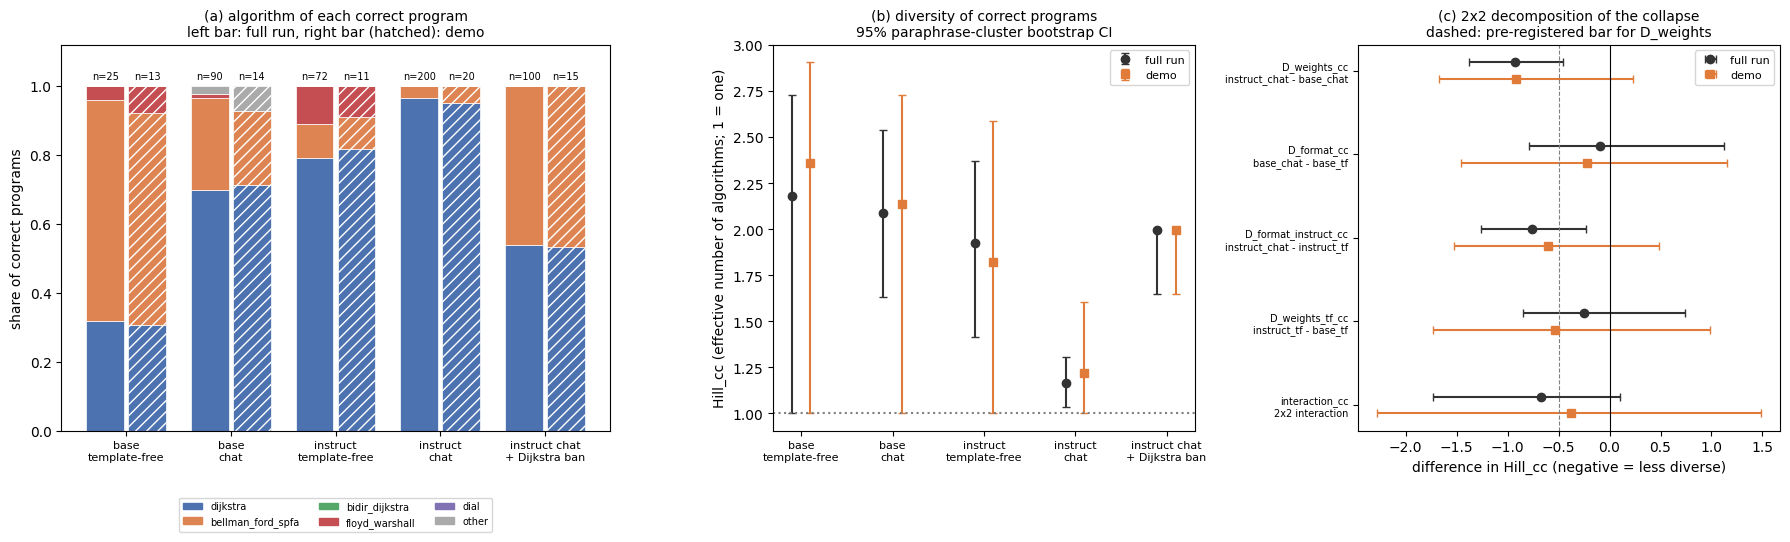

In [20]:
LABS = CATALOGUE["t2"] + ["other"]
COLORS = {"dijkstra": "#4C72B0", "bellman_ford_spfa": "#DD8452", "bidir_dijkstra": "#55A868",
          "floyd_warshall": "#C44E52", "dial": "#8172B3", "other": "#AAAAAA"}
NICE = {"base_tf": "base\ntemplate-free", "base_chat": "base\nchat", "instruct_tf": "instruct\ntemplate-free",
        "instruct_chat": "instruct\nchat", "instruct_chat_ban": "instruct chat\n+ Dijkstra ban"}
# name -> (per-arm summaries, collapse screen, colour, marker, x offset)
SOURCES = {"full run": (ref["arms"], cs_f, "#333333", "o", -0.2), "demo": (demo, cs_d, "#E07B39", "s", 0.2)}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
x = np.arange(len(A_ORDER))

ax = axes[0]  # (a) algorithm mix of the correct programs
for name, (arms_, _, _, _, off) in SOURCES.items():
    for i, a in enumerate(A_ORDER):
        c = arms_[a]["label_counts_correct"]
        tot, bottom = sum(c.values()), 0.0
        for lab in LABS:
            h = c.get(lab, 0) / tot if tot else 0.0
            ax.bar(i + off, h, 0.36, bottom=bottom, color=COLORS[lab], edgecolor="white", linewidth=0.5,
                   hatch="///" if name == "demo" else None)
            bottom += h
        ax.text(i + off, 1.02, f"n={tot}", ha="center", fontsize=7)
ax.set_xticks(x, [NICE[a] for a in A_ORDER], fontsize=8)
ax.set_ylim(0, 1.12)
ax.set_ylabel("share of correct programs")
ax.set_title("(a) algorithm of each correct program\nleft bar: full run, right bar (hatched): demo", fontsize=10)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=COLORS[l]) for l in LABS], LABS, fontsize=7, ncol=3,
          loc="upper center", bbox_to_anchor=(0.5, -0.16))

ax = axes[1]  # (b) Hill_cc per arm
for name, (arms_, _, col, mk, off) in SOURCES.items():
    for i, a in enumerate(A_ORDER):
        h, ci = arms_[a].get("hill_cc"), arms_[a].get("hill_cc_ci") or {}
        if h is None:
            continue
        err = [[max(h - ci["lo"], 0)], [max(ci["hi"] - h, 0)]] if ci.get("lo") is not None else None
        ax.errorbar(i + off / 2, h, yerr=err, fmt=mk, color=col, capsize=3, label=name if i == 0 else None)
ax.axhline(1.0, ls=":", color="gray")
ax.set_xticks(x, [NICE[a] for a in A_ORDER], fontsize=8)
ax.set_ylabel("Hill_cc (effective number of algorithms; 1 = one)")
ax.set_title("(b) diversity of correct programs\n95% paraphrase-cluster bootstrap CI", fontsize=10)
ax.legend(fontsize=8)

ax = axes[2]  # (c) the 2x2 decomposition
for name, (_, cs_, col, mk, off) in SOURCES.items():
    for j, (key, _) in enumerate(EFFECTS):
        d = cs_.get(key) or {}
        est = d.get("est")
        if est is None:
            continue
        err = [[max(est - d["lo"], 0)], [max(d["hi"] - est, 0)]] if d.get("lo") is not None else None
        ax.errorbar(est, len(EFFECTS) - 1 - j - off / 2, xerr=err, fmt=mk, color=col, capsize=3,
                    label=name if j == 0 else None)
ax.axvline(0, color="k", lw=0.8)
ax.axvline(-0.5, color="gray", ls="--", lw=0.8)
ax.set_yticks(range(len(EFFECTS)), [f"{k}\n{d.split('(')[0].strip()}" for k, d in EFFECTS][::-1], fontsize=7)
ax.set_xlabel("difference in Hill_cc (negative = less diverse)")
ax.set_title("(c) 2x2 decomposition of the collapse\ndashed: pre-registered bar for D_weights", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Figure 2: the mechanistic test and the diversity knobs (full run, from `method_out.json`)

These panels plot GPU-phase results that `assemble()` carries into `method_out.json`; the notebook does not recompute them. In the `acts` step both models read the same 50 chat-templated prompts, and the residual stream was saved at the read position R (the last prompt token). The **instruct-minus-base direction** at layer L is δ_L = mean(h_instruct − h_base).

**(a)** δ is very reliable: the split-half cosine is ≥ 0.997 at every layer. It is also largely shared between the two tasks, with cosine 0.84–0.93 inside the steering band (layers 8–28). The two models' mean states are nearly parallel at the embeddings (cos 0.998) but drift apart in the middle layers (cos 0.35–0.62 for T2 inside the band).

**(b)** Inside the band, δ is about as large as the base residual itself (‖δ‖ / ‖h_base‖ ≈ 0.85–1.2). It overlaps only weakly with the difference measured during generation (cos 0.16–0.26 for T2). Through the logit lens at layer 28, subtracting δ suppresses answer-format tokens (```` ``` ````, "here") and promotes chat and prompt tokens ("Conversation", "Prompt", "chat"). That is consistent with δ encoding *how to answer* rather than *which algorithm to use*.

**(c)** Every diversity knob tested on T2. Subtracting c·δ over layers 8–28 destroyed the output format: no parseable program at c = 0.5, 1.0 or 1.5. The single-layer version at layer 18 kept a 98 % pass rate at c ≤ 0.5 with Hill_cc ≤ 1.1, and broke at c = 1.0. Norm-matched random directions over the same band also cost correctness (0 % and 33 % pass). **The one-line prompt ban gives the largest diversity gain, at no pass-rate cost.**

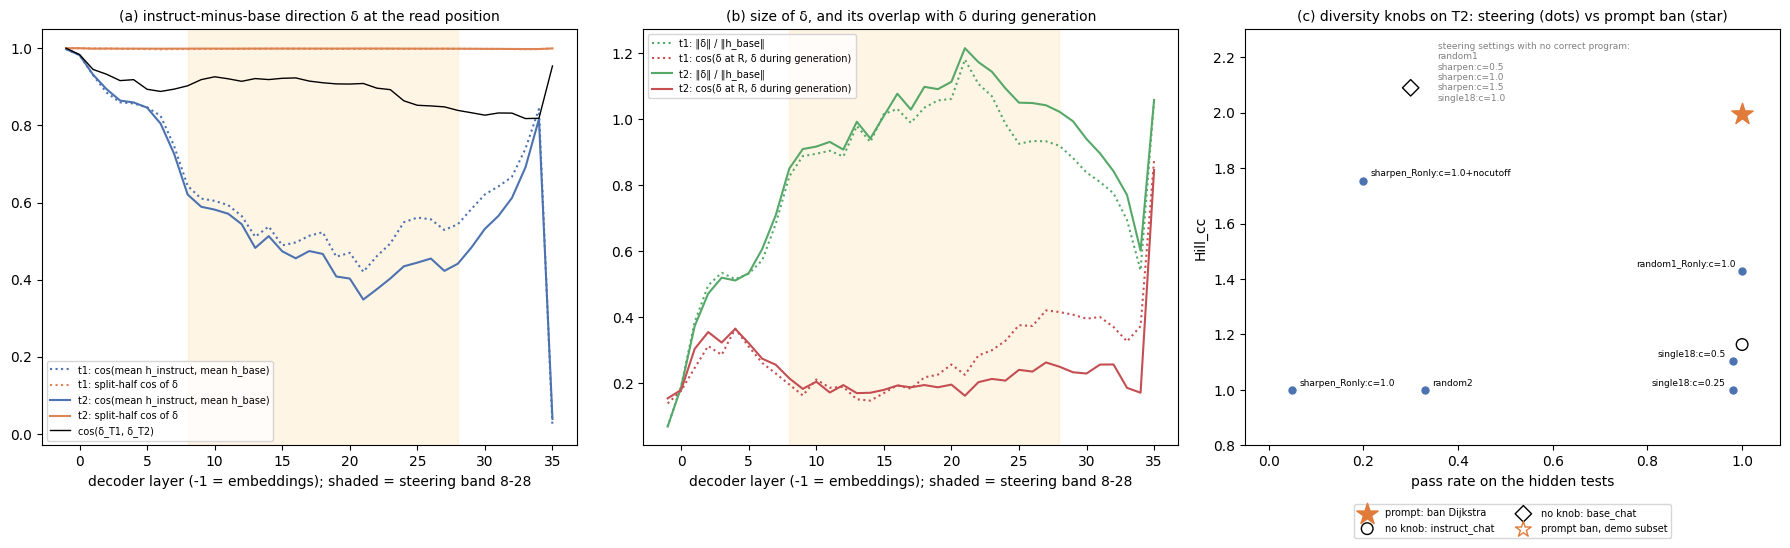

In [21]:
sd = meta["sharpening_direction"]
band = (min(sd["band_layers"]), max(sd["band_layers"]))
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))

for task, ls in (("t1", ":"), ("t2", "-")):
    pl = sd["tasks"][task]["per_layer"]
    L = [p["decoder_layer"] for p in pl]
    axes[0].plot(L, [p["cos_meanI_meanB"] for p in pl], ls=ls, color="#4C72B0", label=f"{task}: cos(mean h_instruct, mean h_base)")
    axes[0].plot(L, [p["split_half_cos"] for p in pl], ls=ls, color="#DD8452", label=f"{task}: split-half cos of δ")
    axes[1].plot(L, [p["rel_norm_delta"] for p in pl], ls=ls, color="#55A868", label=f"{task}: ‖δ‖ / ‖h_base‖")
    axes[1].plot(L, [p["cos_delta_R_delta_gen"] for p in pl], ls=ls, color="#C44E52",
                 label=f"{task}: cos(δ at R, δ during generation)")
tg = sd["task_generality_cos"]
axes[0].plot([g["index"] - 1 for g in tg], [g["cos_delta_t1_t2"] for g in tg], color="k", lw=1, label="cos(δ_T1, δ_T2)")
for ax in axes[:2]:
    ax.axvspan(*band, color="orange", alpha=0.1)
    ax.set_xlabel("decoder layer (-1 = embeddings); shaded = steering band 8-28")
    ax.legend(fontsize=7)
axes[0].set_title("(a) instruct-minus-base direction δ at the read position", fontsize=10)
axes[1].set_title("(b) size of δ, and its overlap with δ during generation", fontsize=10)

ax = axes[2]  # (c) every diversity knob on T2 (full run)
broken = []
for r in ref["BUY_t2"]:
    k = r["knob"].replace("steer:", "")
    if r["knob"].startswith("prompt:"):
        ax.scatter(r["pass_rate"], r["hill_cc"], marker="*", s=260, color="#E07B39", zorder=3, label="prompt: ban Dijkstra")
    elif r["hill_cc"] is None:
        broken.append(k)
    else:
        right = r["pass_rate"] > 0.8
        ax.scatter(r["pass_rate"], r["hill_cc"], color="#4C72B0", s=25, zorder=2)
        ax.annotate(k, (r["pass_rate"], r["hill_cc"]), textcoords="offset points", xytext=(-5 if right else 5, 3),
                    ha="right" if right else "left", fontsize=6.5)
for a, mk in (("instruct_chat", "o"), ("base_chat", "D")):
    s = ref["arms"][a]
    ax.scatter(s["pass_rate"][0], s["hill_cc"], marker=mk, s=70, facecolors="none", edgecolors="k", zorder=3,
               label=f"no knob: {a}")
demo_ban = next((r for r in meta["rows"]["BUY"] if r["knob"].startswith("prompt:")), None)
if demo_ban and demo_ban["hill_cc"] is not None:
    ax.scatter(demo_ban["pass_rate"], demo_ban["hill_cc"], marker="*", s=140, facecolors="none", edgecolors="#E07B39",
               zorder=4, label="prompt ban, demo subset")
ax.text(0.36, 0.97, "steering settings with no correct program:\n" + "\n".join(broken), transform=ax.transAxes,
        fontsize=6.5, va="top", color="gray")
ax.set_xlim(-0.05, 1.08)
ax.set_ylim(0.8, 2.3)
ax.set_xlabel("pass rate on the hidden tests")
ax.set_ylabel("Hill_cc")
ax.set_title("(c) diversity knobs on T2: steering (dots) vs prompt ban (star)", fontsize=10)
ax.legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.13))
fig.tight_layout()
plt.show()

## Summary

* **On T2, post-training installed the collapse by sharpening a preference the base model already had, not by creating a new one.** With identical chat tokens, the base weights spread their correct programs over Dijkstra and Bellman-Ford (Hill_cc ≈ 2.1). The instruct weights put almost all of them on Dijkstra (≈ 1.2). That gives `D_weights` ≈ −0.9, and the pre-registered verdict for T2 is `INSTALLED_BY_POST_TRAINING`. Under the chat template, Dijkstra is already the base model's favourite.
* **The prompt format matters too.** Without the chat template, the base model's favourite is Bellman-Ford, and the instruct model is less collapsed (Hill_cc 1.93 vs 1.16 in the full run).
* **A ban in the prompt substitutes rather than subtracts, and it beats steering.** Under "Do not use Dijkstra", 46 % of the instruct model's programs switch to Bellman-Ford and none fail the tests, so Hill_cc rises from 1.16 to 1.99. The hash-committed forecast named Bellman-Ford in advance. Forecasts built from the base model's chat-template counts, or from the instruct model's own counts, did as well or better (log score −0.06 vs −0.22). Subtracting the instruct-minus-base direction did not restore diversity at any tested strength.
* From 100 programs, the demo recovers the direction and rough size of these effects, but its CIs are too wide for the pre-registered verdict (`D_weights` reaches 0). That is why the experiment extended the base arms to N = 300. The full-run numbers (1,000 T2 programs across these five arms) are the ones to cite.

The full pipeline (`python method.py --all`) needs the experiment's `src/` scripts and a GPU with at least 23 GB of memory.